In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_124.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_949.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_786.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_371.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_599.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_802.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_1323.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_1347.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_955.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_778.jpg
/kaggle/input/datasets/masou

# 1. Import Libraries and check GPU  

In [2]:
import tensorflow as tf
import os
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  2


# 2. Data Loading & Preprocessing

In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [4]:
# 1.Set Dataset folders path
train_path = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training'
test_path = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'

In [5]:
# 2. Data Augmentation & Normalization for Training Data
train_datagen = ImageDataGenerator(
    rescale=1./255,          
    rotation_range=15,       
    horizontal_flip=True,    
    validation_split=0.2     
)

In [6]:
# 3. Training Generator (80% Training)
train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical', 
    subset='training'
)

Found 4480 images belonging to 4 classes.


In [7]:
# 4. Validation Generator (20% Validation)
val_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 1120 images belonging to 4 classes.


In [8]:
# 5. Testing Generator (For final evaluation)
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

Found 1600 images belonging to 4 classes.


# 3. CNN Model Architecture Design

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [10]:
# CNN Model Architecture
model = Sequential([
    Input(shape=(150, 150, 3)), 
    
    # 1st Conv Block
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    
    # 2nd Conv Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    
    # 3rd Conv Block
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    
    # Flatten layer (Convert 2D matrix into 1D vector)
    Flatten(),
    
    # Fully Connected Dense Layers
    Dense(512, activation='relu'),
    Dropout(0.5),
    
     # Output Layer ( 'softmax' for 4 classes)
    Dense(4, activation='softmax')
])

# Summary of model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,035,716 (72.62 MB)

 Trainable params: 19,035,716 (72.62 MB)

 Non-trainable params: 0 (0.00 B)

# 4. Compile Model

In [11]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


# 5. Training Model

In [12]:
# Model Training
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    epochs=10,
    validation_data=val_generator,
    validation_steps=val_generator.samples // val_generator.batch_size
)

Epoch 1/10


E0000 00:00:1794738743.934056      91 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


140/140 ━━━━━━━━━━━━━━━━━━━━ 67s 412ms/step - accuracy: 0.6580 - loss: 0.8387 - val_accuracy: 0.7812 - val_loss: 0.5555
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 44s 316ms/step - accuracy: 0.8165 - loss: 0.4911 - val_accuracy: 0.8277 - val_loss: 0.4413
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 301ms/step - accuracy: 0.8507 - loss: 0.4011 - val_accuracy: 0.8464 - val_loss: 0.3742
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 43s 304ms/step - accuracy: 0.8670 - loss: 0.3437 - val_accuracy: 0.8607 - val_loss: 0.3631
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 44s 316ms/step - accuracy: 0.8978 - loss: 0.2727 - val_accuracy: 0.8839 - val_loss: 0.3327
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 43s 308ms/step - accuracy: 0.9103 - loss: 0.2411 - val_accuracy: 0.8964 - val_loss: 0.2854
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 43s 310ms/step - accuracy: 0.9201 - loss: 0.2044 - val_accuracy: 0.8920 - val_loss: 0.2930
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 303ms/step - accuracy: 0.9321 - loss: 0.1808 - val

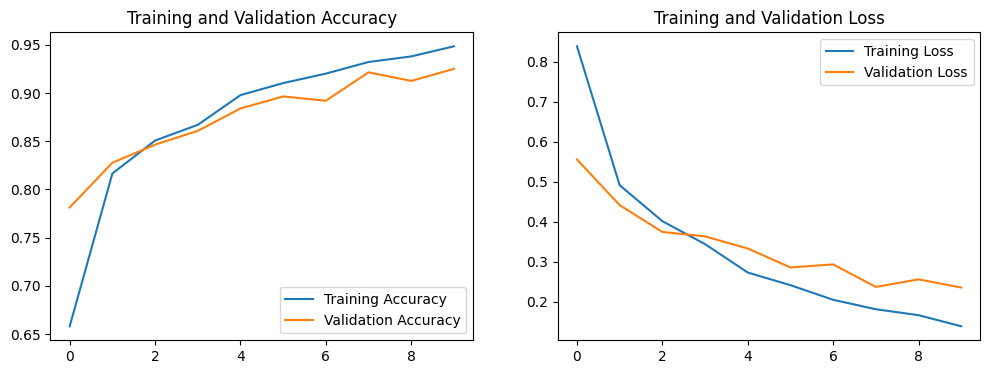

In [13]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

# 7. Evaluate model on Test Dataset

In [14]:
test_loss, test_accuracy = model.evaluate(test_generator)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 157ms/step - accuracy: 0.8844 - loss: 1.0082
Test Loss: 1.0082
Test Accuracy: 88.44%


# Part 2: Transfer Learning using MobileNetV2 (For Higher Accuracy)

# Step 1: Load Pre-trained MobileNetV2 Base Model and Freeze Weights

In [15]:
import warnings
warnings.filterwarnings('ignore') 

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

# Load MobileNetV2 pre-trained on ImageNet, excluding its final classification layers
base_model = MobileNetV2(
    input_shape=(150, 150, 3), 
    include_top=False, 
    weights='imagenet'
)

# Freeze the base model weights so they are not modified during initial training
base_model.trainable = False

print("MobileNetV2 Base Model Loaded and Frozen Successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 Base Model Loaded and Frozen Successfully!


# Step 2: Add Custom Classification Heads and Build Model

In [16]:
# Build custom classification layers on top of the MobileNetV2 base
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)

# Output layer with 4 nodes for multi-class classification (glioma, meningioma, pituitary, notumor)
outputs = Dense(4, activation='softmax')(x)

# Combine base model and custom layers into a single transfer learning model
transfer_model = Model(inputs=base_model.input, outputs=outputs)

# Display the summary of the transfer learning model architecture
transfer_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 75, 75,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 75, 75,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 75, 75,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 75, 75,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 75, 75,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 75, 75,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 77, 77,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 38, 38,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 38, 38,    │      2,304 │ block_1_depthwis

 Total params: 2,915,908 (11.12 MB)

 Trainable params: 657,924 (2.51 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Step 3: Compile and Train the Transfer Learning Model

In [17]:
# Compile the transfer learning model with Adam optimizer and categorical crossentropy loss
transfer_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the transfer learning model for 10 epochs
history_transfer = transfer_model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    epochs=10,
    validation_data=val_generator,
    validation_steps=val_generator.samples // val_generator.batch_size
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 57s 323ms/step - accuracy: 0.7828 - loss: 0.5918 - val_accuracy: 0.8589 - val_loss: 0.3525
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 291ms/step - accuracy: 0.8504 - loss: 0.3953 - val_accuracy: 0.9089 - val_loss: 0.2797
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 303ms/step - accuracy: 0.8759 - loss: 0.3311 - val_accuracy: 0.9009 - val_loss: 0.2546
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 301ms/step - accuracy: 0.8893 - loss: 0.2854 - val_accuracy: 0.9000 - val_loss: 0.2600
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 293ms/step - accuracy: 0.9022 - loss: 0.2649 - val_accuracy: 0.9116 - val_loss: 0.2401
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 294ms/step - accuracy: 0.9045 - loss: 0.2522 - val_accuracy: 0.8955 - val_loss: 0.2756
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 301ms/step - accuracy: 0.9069 - loss: 0.2411 - val_accuracy: 0.9161 - val_loss: 0.2254
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 294ms/step - accuracy: 0.9076 - loss: 0

# Step 4: Evaluate MobileNetV2 on Test Dataset

In [18]:
# Evaluate the transfer learning model on the unseen test dataset
test_loss_tl, test_accuracy_tl = transfer_model.evaluate(test_generator)

print(f"MobileNetV2 Test Loss: {test_loss_tl:.4f}")
print(f"MobileNetV2 Test Accuracy: {test_accuracy_tl * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.8281 - loss: 0.6972
MobileNetV2 Test Loss: 0.6972
MobileNetV2 Test Accuracy: 82.81%


# Step 5: Model Comparison & Visualization (Custom CNN vs MobileNetV2)

--- Model Performance Comparison ---


,Model,Validation Accuracy (%),Test Accuracy (%),Test Loss
0,Custom CNN (Scratch),92.50,88.44,1.0082
1,MobileNetV2 (Frozen Base),92.86,82.81,0.6972


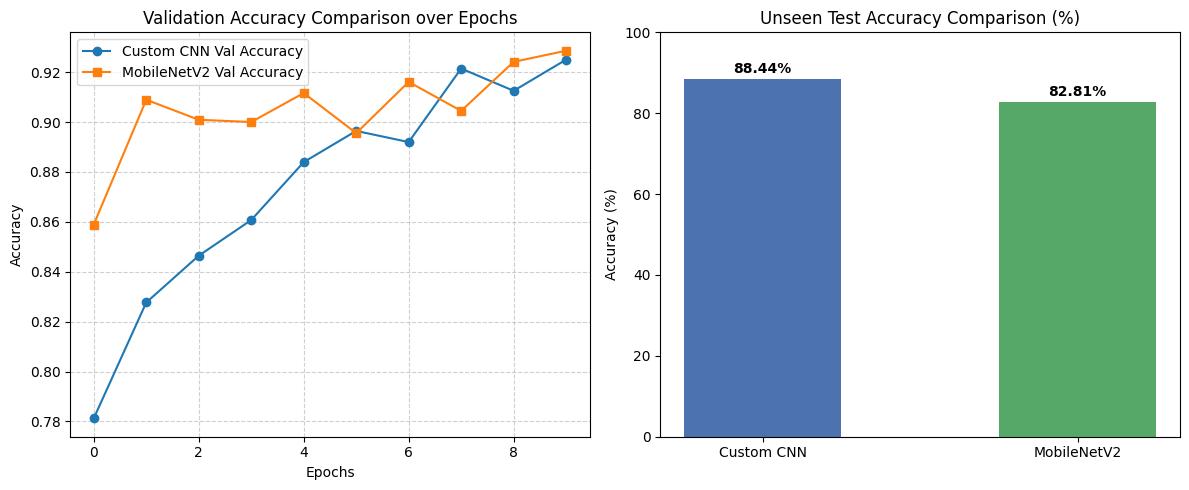

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a summary comparison table using pandas DataFrame
comparison_data = {
    'Model': ['Custom CNN (Scratch)', 'MobileNetV2 (Frozen Base)'],
    'Validation Accuracy (%)': [round(max(history.history['val_accuracy']) * 100, 2), 
                                round(max(history_transfer.history['val_accuracy']) * 100, 2)],
    'Test Accuracy (%)': [round(test_accuracy * 100, 2), 
                          round(test_accuracy_tl * 100, 2)],
    'Test Loss': [round(test_loss, 4), 
                  round(test_loss_tl, 4)]
}

comparison_df = pd.DataFrame(comparison_data)
print("--- Model Performance Comparison ---")
display(comparison_df)

# Plot side-by-side comparison of Validation Accuracy and Test Accuracy
plt.figure(figsize=(12, 5))

# Plot 1: Validation Accuracy Curve Comparison
plt.subplot(1, 2, 1)
plt.plot(history.history['val_accuracy'], label='Custom CNN Val Accuracy', marker='o')
plt.plot(history_transfer.history['val_accuracy'], label='MobileNetV2 Val Accuracy', marker='s')
plt.title('Validation Accuracy Comparison over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Final Test Accuracy Bar Chart
plt.subplot(1, 2, 2)
models = ['Custom CNN', 'MobileNetV2']
test_accs = [test_accuracy * 100, test_accuracy_tl * 100]
bars = plt.bar(models, test_accs, color=['#4C72B0', '#55A868'], width=0.5)
plt.title('Unseen Test Accuracy Comparison (%)')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

# Add exact percentage labels on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{yval:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()